<a href="https://colab.research.google.com/github/braysonimbambi455/CSC4110-G03/blob/main/notebooks/G03_U8_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error

# Connect Google Drive
drive.mount('/content/drive')

# Set project folders
PROJECT_DIR = "/content/drive/MyDrive/CSC4110_G03"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load cleaned dataset
df_clean = pd.read_csv(os.path.join(DATA_DIR, "clean_crops.csv"))

print("Dataset shape:", df_clean.shape)
print(df_clean.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (25932, 19)
          Item  Year  yield_hg_ha  rain_mm  pesticides_t  avg_temp  log_yield  \
0        Maize  1990        36613   1485.0         121.0     16.37  10.508159   
1     Potatoes  1990        66667   1485.0         121.0     16.37  11.107465   
2  Rice, paddy  1990        23333   1485.0         121.0     16.37  10.057624   
3      Sorghum  1990        12500   1485.0         121.0     16.37   9.433484   
4     Soybeans  1990         7000   1485.0         121.0     16.37   8.853665   

   Area_frequency  Item_Cassava  Item_Maize  Item_Plantains and others  \
0        0.003818             0           1                          0   
1        0.003818             0           0                          0   
2        0.003818             0           0                          0   
3        0.003818             0           0                  

In [ ]:

# Implement a single perceptron using NumPy

# AND truth table
X_and = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_and = np.array([0, 0, 0, 1])

# Initialise weights and bias
w_and = np.zeros(2)
b_and = 0.0

# Step activation function
def step_activation(z):
    return 1 if z >= 0 else 0

# Train the perceptron
learning_rate = 0.1
epochs = 20

for epoch in range(epochs):
    for inputs, target in zip(X_and, y_and):
        prediction = step_activation(np.dot(inputs, w_and) + b_and)
        error = target - prediction

        w_and += learning_rate * error * inputs
        b_and += learning_rate * error

# Display final weights and bias
print("Final weights:", w_and)
print("Final bias:", b_and)

# Test the trained perceptron
print("\nAND predictions:")
for inputs in X_and:
    prediction = step_activation(np.dot(inputs, w_and) + b_and)
    print(inputs, "=", prediction)


Final weights: [0.2 0.1]
Final bias: -0.20000000000000004

AND predictions:
[0 0] = 0
[0 1] = 0
[1 0] = 0
[1 1] = 1


In [ ]:

# XOR truth table
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])

# Reset weights and bias
w_xor = np.zeros(2)
b_xor = 0.0

# Train the single perceptron on XOR
for epoch in range(100):
    for inputs, target in zip(X_xor, y_xor):
        prediction = step_activation(np.dot(inputs, w_xor) + b_xor)
        error = target - prediction

        w_xor += learning_rate * error * inputs
        b_xor += learning_rate * error

# Display predictions
print("XOR predictions:")
for inputs, target in zip(X_xor, y_xor):
    prediction = step_activation(np.dot(inputs, w_xor) + b_xor)
    print(inputs, "Expected:", target, "Predicted:", prediction)

print("Final XOR weights:", w_xor)
print("Final XOR bias:", b_xor)


XOR predictions:
[0 0] Expected: 0 Predicted: 1
[0 1] Expected: 1 Predicted: 1
[1 0] Expected: 1 Predicted: 0
[1 1] Expected: 0 Predicted: 0
Final XOR weights: [-0.1  0. ]
Final XOR bias: 0.0


### Why a single perceptron fails on XOR

A single perceptron fails to learn XOR because XOR is not linearly separable. This means that one straight decision boundary cannot correctly separate the two output classes. A single perceptron can learn simple operations such as AND, but XOR requires a more complex model with at least one hidden layer.

In [ ]:

# Prepare features and target for crop classification

features = ["rain_mm", "pesticides_t", "avg_temp", "Year", "Area_frequency"]

X_clf = df_clean[features]
y_clf = df_clean["Item"]

# Use the same chronological split as Task 2.2
train_mask = df_clean["Year"] <= 2009
test_mask = (df_clean["Year"] >= 2010) & (df_clean["Year"] <= 2013)

X_train_clf = X_clf.loc[train_mask]
X_test_clf = X_clf.loc[test_mask]

y_train_clf = y_clf.loc[train_mask]
y_test_clf = y_clf.loc[test_mask]

# Scale features using training data only
scaler_clf = StandardScaler()

X_train_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_scaled = scaler_clf.transform(X_test_clf)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)
print("Crop classes:", y_clf.nunique())


Training data: (21305, 5)
Testing data: (4627, 5)
Crop classes: 10


In [ ]:

# Compare three MLPClassifier architectures

architectures = [(16,), (32, 16), (64, 32, 16)]

mlp_results = []

for architecture in architectures:
    model = MLPClassifier(
        hidden_layer_sizes=architecture,
        activation="relu",
        max_iter=300,
        random_state=42
    )

    model.fit(X_train_scaled, y_train_clf)
    predictions = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test_clf, predictions)
    f1 = f1_score(y_test_clf, predictions, average="macro")

    mlp_results.append({
        "hidden_layers": architecture,
        "test_accuracy": accuracy,
        "test_f1": f1
    })

mlp_results = pd.DataFrame(mlp_results)

print(mlp_results)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


  hidden_layers  test_accuracy   test_f1
0         (16,)       0.154528  0.127211
1      (32, 16)       0.154744  0.130228
2  (64, 32, 16)       0.154096  0.141380


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


In [ ]:

# Select the architecture with the highest macro F1-score
best_architecture = mlp_results.loc[
    mlp_results["test_f1"].idxmax(), "hidden_layers"
]

# Train the selected neural network
best_mlp = MLPClassifier(
    hidden_layer_sizes=best_architecture,
    activation="relu",
    max_iter=500,
    random_state=42
)

best_mlp.fit(X_train_scaled, y_train_clf)

print("Best architecture:", best_architecture)
print("Best model test accuracy:",
      accuracy_score(y_test_clf, best_mlp.predict(X_test_scaled)))
print("Best model macro F1:",
      f1_score(y_test_clf, best_mlp.predict(X_test_scaled),
               average="macro"))

Best architecture: (64, 32, 16)
Best model test accuracy: 0.15668899935163172
Best model macro F1: 0.1421018832969158


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


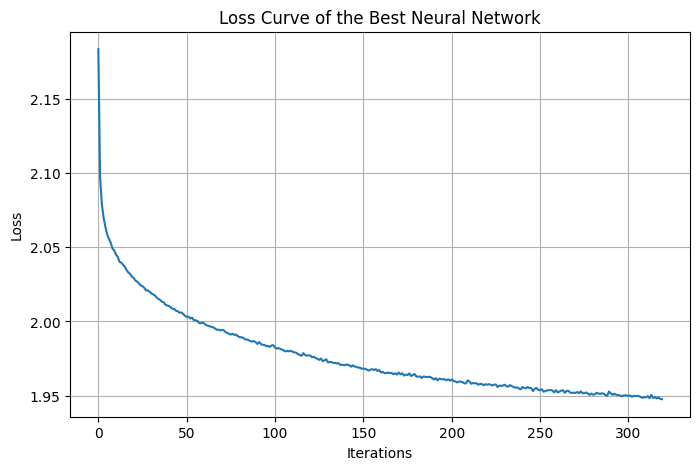

In [ ]:

# Plot and save the best neural network's loss curve

plt.figure(figsize=(8, 5))
plt.plot(best_mlp.loss_curve_)
plt.title("Loss Curve of the Best Neural Network")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)

plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"))
plt.show()

In [ ]:

# Encode crop names into numerical labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train_clf)
y_test_encoded = label_encoder.transform(y_test_clf)

print("Crop classes:", label_encoder.classes_)
print("Training labels:", y_train_encoded[:10])
print("Testing labels:", y_test_encoded[:10])


Crop classes: ['Cassava' 'Maize' 'Plantains and others' 'Potatoes' 'Rice, paddy'
 'Sorghum' 'Soybeans' 'Sweet potatoes' 'Wheat' 'Yams']
Training labels: [1 3 4 5 6 8 1 3 4 5]
Testing labels: [1 3 6 8 1 3 6 8 1 3]


In [ ]:

# Restore the required neural network imports
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error
from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("Imports restored successfully")


Imports restored successfully


In [ ]:

# Restore the best neural network architecture
best_architecture = (64, 32, 16)

print("Selected architecture:", best_architecture)


Selected architecture: (64, 32, 16)


In [ ]:

# COMPLETE RECOVERY: Restore all classification variables

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error

# Connect Google Drive
drive.mount('/content/drive')

# Project paths
PROJECT_DIR = "/content/drive/MyDrive/CSC4110_G03"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load cleaned dataset
df_clean = pd.read_csv(os.path.join(DATA_DIR, "clean_crops.csv"))

# Prepare classification features and target
features = ["rain_mm", "pesticides_t", "avg_temp",
            "Year", "Area_frequency"]

X_clf = df_clean[features].copy()
y_clf = df_clean["Item"].copy()

# Chronological training and testing split
train_mask = df_clean["Year"] <= 2009
test_mask = (df_clean["Year"] >= 2010) & (df_clean["Year"] <= 2013)

X_train_clf = X_clf.loc[train_mask]
X_test_clf = X_clf.loc[test_mask]

y_train_clf = y_clf.loc[train_mask]
y_test_clf = y_clf.loc[test_mask]

# Scale using training data only
scaler_clf = StandardScaler()
X_train_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_scaled = scaler_clf.transform(X_test_clf)

# Encode crop labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_clf)
y_test_encoded = label_encoder.transform(y_test_clf)

# Restore best architecture from previous experiment
best_architecture = (64, 32, 16)

# Confirm that all variables are ready
print("RECOVERY SUCCESSFUL")
print("Dataset:", df_clean.shape)
print("Training features:", X_train_scaled.shape)
print("Testing features:", X_test_scaled.shape)
print("Number of crop classes:", len(label_encoder.classes_))
print("Best architecture:", best_architecture)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RECOVERY SUCCESSFUL
Dataset: (25932, 19)
Training features: (21305, 5)
Testing features: (4627, 5)
Number of crop classes: 10
Best architecture: (64, 32, 16)


In [ ]:

# Train the selected best neural network

best_mlp = MLPClassifier(
    hidden_layer_sizes=best_architecture,
    activation="relu",
    max_iter=500,
    random_state=42
)

best_mlp.fit(X_train_scaled, y_train_encoded)

predictions = best_mlp.predict(X_test_scaled)

print("Best architecture:", best_architecture)
print("Test accuracy:",
      accuracy_score(y_test_encoded, predictions))
print("Test macro F1:",
      f1_score(y_test_encoded, predictions, average="macro"))


Best architecture: (64, 32, 16)
Test accuracy: 0.1534471579857359
Test macro F1: 0.12027649911991553


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


In [ ]:

# Train the best neural network with early stopping

best_mlp_early = MLPClassifier(
    hidden_layer_sizes=best_architecture,
    activation="relu",
    max_iter=500,
    early_stopping=True,
    random_state=42
)

best_mlp_early.fit(X_train_scaled, y_train_encoded)

# Evaluate early stopping model
early_predictions = best_mlp_early.predict(X_test_scaled)

early_accuracy = accuracy_score(y_test_encoded, early_predictions)
early_f1 = f1_score(y_test_encoded, early_predictions, average="macro")

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Without Early Stopping", "With Early Stopping"],
    "Accuracy": [
        accuracy_score(y_test_encoded, best_mlp.predict(X_test_scaled)),
        early_accuracy
    ],
    "Macro F1": [
        f1_score(y_test_encoded, best_mlp.predict(X_test_scaled), average="macro"),
        early_f1
    ]
})

print(comparison)


                    Model  Accuracy  Macro F1
0  Without Early Stopping  0.153447  0.120276
1     With Early Stopping  0.156041  0.104415


In [ ]:

# Compare ReLU, tanh and logistic activation functions

activation_results = []

for activation in ["relu", "tanh", "logistic"]:
    model = MLPClassifier(
        hidden_layer_sizes=best_architecture,
        activation=activation,
        max_iter=500,
        early_stopping=True,
        random_state=42
    )

    model.fit(X_train_scaled, y_train_encoded)

    predictions = model.predict(X_test_scaled)

    activation_results.append({
        "activation": activation,
        "accuracy": accuracy_score(y_test_encoded, predictions),
        "f1_score": f1_score(y_test_encoded, predictions, average="macro")
    })

activation_results = pd.DataFrame(activation_results)

print(activation_results)


  activation  accuracy  f1_score
0       relu  0.156041  0.104415
1       tanh  0.155392  0.135690
2   logistic  0.157121  0.059937


In [ ]:

# Prepare regression features and target

y_reg = df_clean["log_yield"]

X_reg = df_clean.drop(
    columns=["log_yield", "yield_hg_ha", "Item", "Year"]
)

train_mask = df_clean["Year"] <= 2009
test_mask = (df_clean["Year"] >= 2010) & (df_clean["Year"] <= 2013)

X_train_reg = X_reg.loc[train_mask]
X_test_reg = X_reg.loc[test_mask]

y_train_reg = y_reg.loc[train_mask]
y_test_reg = y_reg.loc[test_mask]

# Scale using training data only
scaler_reg = StandardScaler()

X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Training shape:", X_train_reg_scaled.shape)
print("Testing shape:", X_test_reg_scaled.shape)


Training shape: (21305, 15)
Testing shape: (4627, 15)


In [ ]:

# Train an MLP regressor

mlp_reg = MLPRegressor(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    max_iter=500,
    random_state=42
)

mlp_reg.fit(X_train_reg_scaled, y_train_reg)

# Calculate test RMSE
reg_predictions = mlp_reg.predict(X_test_reg_scaled)

mlp_reg_rmse = np.sqrt(
    mean_squared_error(y_test_reg, reg_predictions)
)

print("MLP Regression Test RMSE:", mlp_reg_rmse)


MLP Regression Test RMSE: 0.3879754235764066


In [ ]:

# Display the neural network regression result
print("MLP regression test RMSE:", mlp_reg_rmse)


MLP regression test RMSE: 0.3879754235764066
